## Use as dataset the one given by step_0

In [1]:
import pandas as pd

candidates = pd.read_csv("candidates.csv")

sbert_results = pd.read_csv("sbert_results.csv.gz", compression="gzip")

# 2. Merge SBERT similarity scores back into candidates
df_ranked = candidates.merge(sbert_results, on="appln_id", how="left")
df_ranked = df_ranked.sort_values("sbert_similarity", ascending=False).reset_index(drop=True)

SIMILARITY_THRESHOLD = 0.60
final_dataset = df_ranked[df_ranked["sbert_similarity"] >= SIMILARITY_THRESHOLD].copy()

# 4. Print summary metrics
print(f"✅ Total baseline candidates: {len(candidates):,} patents")
print(f"🎯 Target dataset (Similarity >= {SIMILARITY_THRESHOLD*100:.0f}%): {len(final_dataset):,} patents")
if len(final_dataset) > 0:
    print(f"📊 Similarity range in target: {final_dataset['sbert_similarity'].min():.4f} to {final_dataset['sbert_similarity'].max():.4f}")


✅ Total baseline candidates: 196,524 patents
🎯 Target dataset (Similarity >= 60%): 48,930 patents
📊 Similarity range in target: 0.6000 to 0.9840


In [2]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

In [3]:
ENV = "TEST"                 # develop on TEST, switch to "PROD" for final numbers if requested
OUTPUT_DIR = Path("outputs")

# ---------------------------------------------------------------- sector definition (SBERT Approach)
SECTOR_NAME = "Utility-Scale Energy Storage"
SIMILARITY_THRESHOLD = 0.60  # SBERT score cutoff (replaces raw CPC prefix filters)

# ---------------------------------------------------------------- time window
YEAR_MIN, YEAR_MAX = 2000, 2025

# Dating choice (PW Rules)
FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: earliest priority year
APPLN_TIME_COLUMN = "appln_filing_year"        # application level: application's filing year

# Last years incomplete in PATSTAT due to publication lag
TRUNCATED_YEARS = {"appln_filing_year": 3, "earliest_filing_year": 3, "earliest_publn_year": 1}

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                # Patents of Invention only
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # Major 5 patent offices
TOP_N = 8                                       # Categories shown in plots/tables

# ---------------------------------------------------------------- derived parameters
LAST_COMPLETE_YEAR = YEAR_MAX - max(TRUNCATED_YEARS[FAMILY_TIME_COLUMN], TRUNCATED_YEARS[APPLN_TIME_COLUMN])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Initialize PATSTAT client & ORM session
patstat = PatstatClient(env=ENV)
db = patstat.orm()

print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR}")

Sector: Utility-Scale Energy Storage | env: TEST | years 2000-2025 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022


## Selecting the sector

In [4]:
# 1. Extract application IDs to map
appln_ids = df_ranked["appln_id"].dropna().astype(int).tolist()
CHUNK_SIZE = 25000
fam_dfs = []

print(f" Fetching docdb_family_id mapping in chunks ({len(appln_ids):,} patents)...")

# 2. Query BigQuery in chunks to stay well under the 1 MB text limit
for i in range(0, len(appln_ids), CHUNK_SIZE):
    chunk_ids = appln_ids[i : i + CHUNK_SIZE]
    q_fam = db.query(
        TLS201_APPLN.appln_id.label("appln_id"),
        TLS201_APPLN.docdb_family_id.label("docdb_family_id")
    ).filter(TLS201_APPLN.appln_id.in_(chunk_ids))
    
    fam_dfs.append(patstat.df(q_fam))

# 3. Combine chunk results into a single mapping DataFrame
fam_mapping = pd.concat(fam_dfs, ignore_index=True)
fam_mapping.columns = ["appln_id", "docdb_family_id"]

if "docdb_family_id" in df_ranked.columns:
    df_ranked = df_ranked.drop(columns=["docdb_family_id"])

# 4. Merge mapping into df_ranked and update target set
df_ranked = df_ranked.merge(fam_mapping, on="appln_id", how="left")
final_enel_dataset = df_ranked[df_ranked["sbert_similarity"] >= SIMILARITY_THRESHOLD].copy()

sector_family_ids = set(
    int(x) for x in final_enel_dataset["docdb_family_id"].dropna().unique()
)

print("docdb_family_id attached successfully!")
print(f"Unique target families (SBERT >= {SIMILARITY_THRESHOLD*100:.0f}%): {len(sector_family_ids):,}")

 Fetching docdb_family_id mapping in chunks (196,524 patents)...
docdb_family_id attached successfully!
Unique target families (SBERT >= 60%): 40,826


## Application

In [5]:
# 1. Identify the largest patent family in our SBERT target set using pandas
family_app_counts = final_enel_dataset["docdb_family_id"].value_counts()
example_family_id = int(family_app_counts.index[0])
apps_in_target_count = family_app_counts.iloc[0]

print(f"Selected Example Family ID: {example_family_id}")
print(f"Target filings in this dataset: {apps_in_target_count} applications\n")

# 2. Query all application records for this family directly from PATSTAT
q_example_family = (
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_size,
    )
    .filter(TLS201_APPLN.docdb_family_id == example_family_id)
    .order_by(TLS201_APPLN.appln_filing_date)
)

example_family = patstat.df(q_example_family)

example_family

Selected Example Family ID: 63669288
Target filings in this dataset: 33 applications



,docdb_family_id,appln_id,appln_auth,appln_kind,appln_filing_date,appln_filing_year,earliest_publn_year,earliest_filing_year,granted,docdb_family_size
0,63669288,500778272,US,A,2018-05-07,2018,2018,2016,N,107
1,63669288,500783187,US,A,2018-05-07,2018,2018,2016,Y,107
2,63669288,500782752,US,A,2018-05-07,2018,2018,2016,Y,107
3,63669288,500783193,US,A,2018-05-07,2018,2018,2016,Y,107
4,63669288,501667906,US,A,2018-05-07,2018,2018,2016,Y,107
5,63669288,500783039,US,A,2018-05-07,2018,2018,2016,Y,107
6,63669288,500783854,US,A,2018-05-07,2018,2018,2016,N,107
7,63669288,500788490,US,A,2018-05-07,2018,2018,2016,N,107
8,63669288,500778685,US,A,2018-05-07,2018,2018,2016,Y,107
9,63669288,500783701,US,A,2018-05-07,2018,2018,2016,Y,107


## Year

In [6]:
years = example_family[["appln_id", "appln_auth", "appln_filing_year", "earliest_publn_year", "earliest_filing_year"]]
family_year = example_family["earliest_filing_year"].min()
print(f"Family {example_family_id}: {len(example_family)} applications filed between "
      f"{example_family['appln_filing_year'].min()} and {example_family['appln_filing_year'].max()}; "
      f"family year (earliest priority) = {family_year}")
years

Family 63669288: 59 applications filed between 2018 and 2019; family year (earliest priority) = 2016


,appln_id,appln_auth,appln_filing_year,earliest_publn_year,earliest_filing_year
0,500778272,US,2018,2018,2016
1,500783187,US,2018,2018,2016
2,500782752,US,2018,2018,2016
3,500783193,US,2018,2018,2016
4,501667906,US,2018,2018,2016
5,500783039,US,2018,2018,2016
6,500783854,US,2018,2018,2016
7,500788490,US,2018,2018,2016
8,500778685,US,2018,2018,2016
9,500783701,US,2018,2018,2016


In [7]:
appln_ids = df_ranked["appln_id"].dropna().astype(int).tolist()
CHUNK_SIZE = 25000
auth_dfs = []

for i in range(0, len(appln_ids), CHUNK_SIZE):
    chunk_ids = appln_ids[i : i + CHUNK_SIZE]
    q_auth = db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth
    ).filter(TLS201_APPLN.appln_id.in_(chunk_ids))
    
    auth_dfs.append(patstat.df(q_auth))

auth_mapping = pd.concat(auth_dfs, ignore_index=True)

# Merge into df_ranked and update target subset
df_ranked = df_ranked.merge(auth_mapping, on="appln_id", how="left")
final_enel_dataset = df_ranked[df_ranked["sbert_similarity"] >= SIMILARITY_THRESHOLD].copy()

# 2. Flag PCT Applications and Families
final_enel_dataset["is_pct"] = final_enel_dataset["appln_auth"] == "WO"

pct_families = set(final_enel_dataset[final_enel_dataset["is_pct"]]["docdb_family_id"].dropna())
final_enel_dataset["family_is_pct"] = final_enel_dataset["docdb_family_id"].isin(pct_families)

# 3. Print PCT shares for technical appendix
pct_app_share = (final_enel_dataset["is_pct"].sum() / len(final_enel_dataset)) * 100
pct_fam_share = (len(pct_families) / final_enel_dataset["docdb_family_id"].nunique()) * 100

print(f"\n PCT INTERNATIONAL FILINGS:")
print(f"  • PCT Applications (WO authority): {final_enel_dataset['is_pct'].sum():,} ({pct_app_share:.1f}%)")
print(f"  • PCT Families (at least 1 WO filing): {len(pct_families):,} ({pct_fam_share:.1f}%)")


 PCT INTERNATIONAL FILINGS:
  • PCT Applications (WO authority): 3,252 (6.6%)
  • PCT Families (at least 1 WO filing): 3,230 (7.9%)


### Functions for the next steps

In [8]:
# ==============================================================================
# SECTION 6: Helper Infrastructure - Scopes, Counting Functions & Visualization
# ==============================================================================

from dataclasses import dataclass
from matplotlib.ticker import PercentFormatter


IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only target families (supports both SQL subqueries and Python sets/lists)."""
    if family_ids is None:
        return q
    if hasattr(family_ids, "subquery"):
        return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))
    return q.filter(TLS201_APPLN.docdb_family_id.in_(list(family_ids)))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents" or sector name
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit


# Instantiate the 4 Scopes using our SBERT sector_family_ids
SCOPES = [
    Scope("all patents", "family", family_scope()),
    Scope(SECTOR_NAME, "family", family_scope(sector_family_ids)),
    Scope("all patents", "application", application_scope()),
    Scope(SECTOR_NAME, "application", application_scope(sector_family_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]

# ------------------------------------------------------------------------------
# 6.2 Counting Functions
# ------------------------------------------------------------------------------
def _join_applications(q, scope):
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    sq = scope.sq
    q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    pairs = unit_category.distinct().subquery()
    k = db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(patstat.df(q), scope)


def fractional_by_country(scope, role="applicant"):
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)
    persons = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, ctry.label("ctry")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(seq_nr > 0, ctry.isnot(None), ctry != "")
        .subquery()
    )
    k = db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.ctry, persons.c.year)
    )
    return _tag(patstat.df(q), scope).assign(role=role)


def fractional_by_cpc_subclass(scope):
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    sq = scope.sq
    unit_field = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(patstat.df(q), scope)


def count_by_office(scope):
    sq = scope.sq
    q = (
        _join_applications(
            db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(patstat.df(q), scope)


def scope_profile(scope):
    sq = scope.sq
    q = db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(patstat.df(q), scope)

# ------------------------------------------------------------------------------
# 6.3 Pandas & Plot Helpers
# ------------------------------------------------------------------------------
def shade_truncated(ax):
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0, label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

print("✅ Section 6 infrastructure functions loaded successfully!")

✅ Section 6 infrastructure functions loaded successfully!


## How big is the sector, and is it growing?

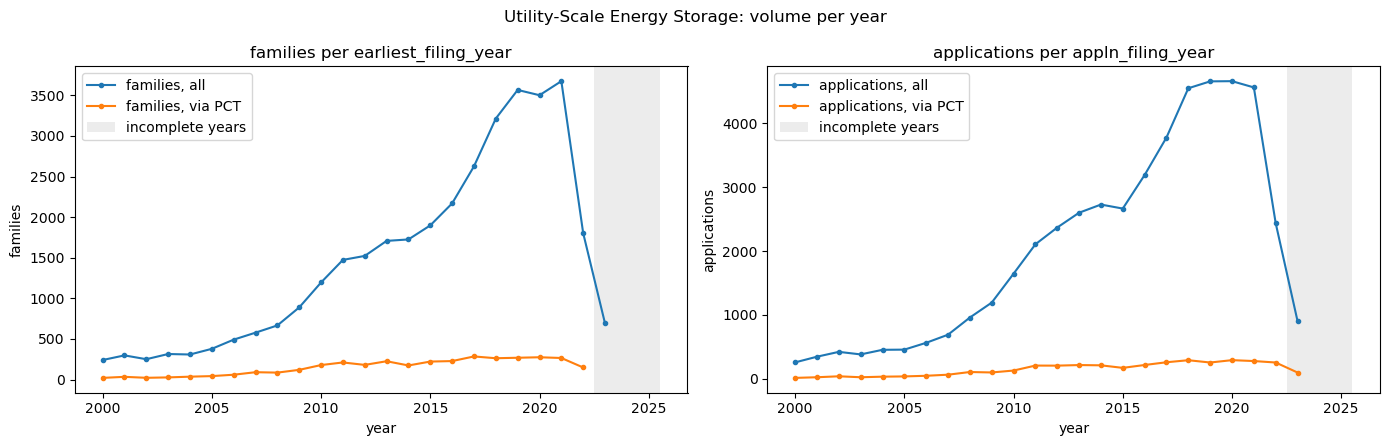

In [9]:
# ------------------------------------------------------------------------------
# 7.0 Volume per Year (Families & Applications, Total vs PCT)
# ------------------------------------------------------------------------------
volume = pd.concat(
    [count_per_year(s).assign(series="all") for s in SCOPES]
    + [count_per_year(s, only_pct=True).assign(series="via PCT") for s in SCOPES],
    ignore_index=True,
)

fig, axes = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
for ax, scope in zip(axes, SECTOR_SCOPES):
    data = volume.query("scope == @scope.name and level == @scope.level")
    for series, grp in data.groupby("series"):
        ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=f"{UNIT_LABEL[scope.level]}, {series}")
    shade_truncated(ax)
    year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
    ax.set(title=f"{UNIT_LABEL[scope.level]} per {year_col}", xlabel="year", ylabel=UNIT_LABEL[scope.level])
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sector_volume_per_year.png", dpi=300)
plt.show()


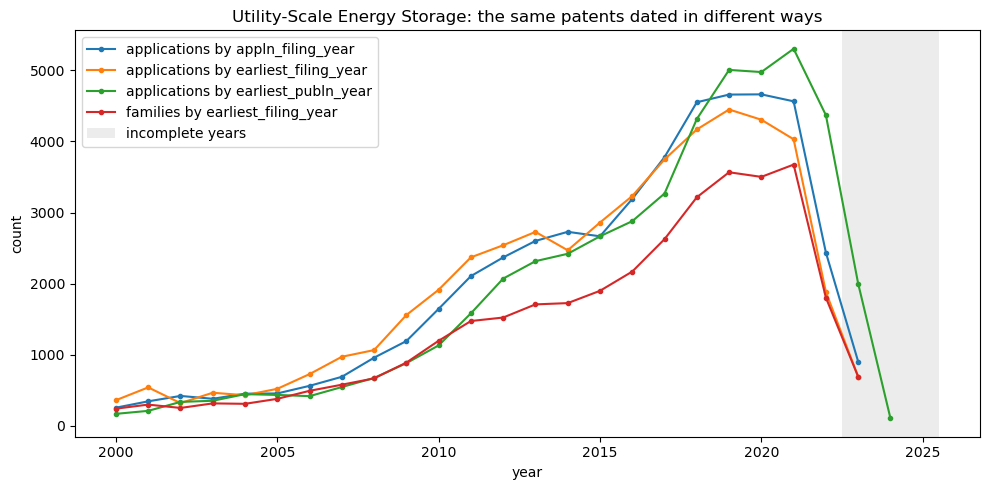

In [10]:
# ==============================================================================
# SECTION 7.1: The same sector, three ways to date it
# ==============================================================================

dating = pd.concat(
    [
        count_per_year(Scope(SECTOR_NAME, "application", application_scope(sector_family_ids, col)))
        .assign(series=f"applications by {col}")
        for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")
    ]
    + [
        volume.query("scope == @SECTOR_NAME and level == 'family' and series == 'all'")
        .assign(series=f"families by {FAMILY_TIME_COLUMN}")
    ],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(10, 5))
for series, grp in dating.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=series)

shade_truncated(ax)
ax.set(
    title=f"{SECTOR_NAME}: the same patents dated in different ways",
    xlabel="year",
    ylabel="count",
)
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dating_comparison.png", dpi=300)
plt.show()

SUMMARY TABLE: Growth (2000–2022)


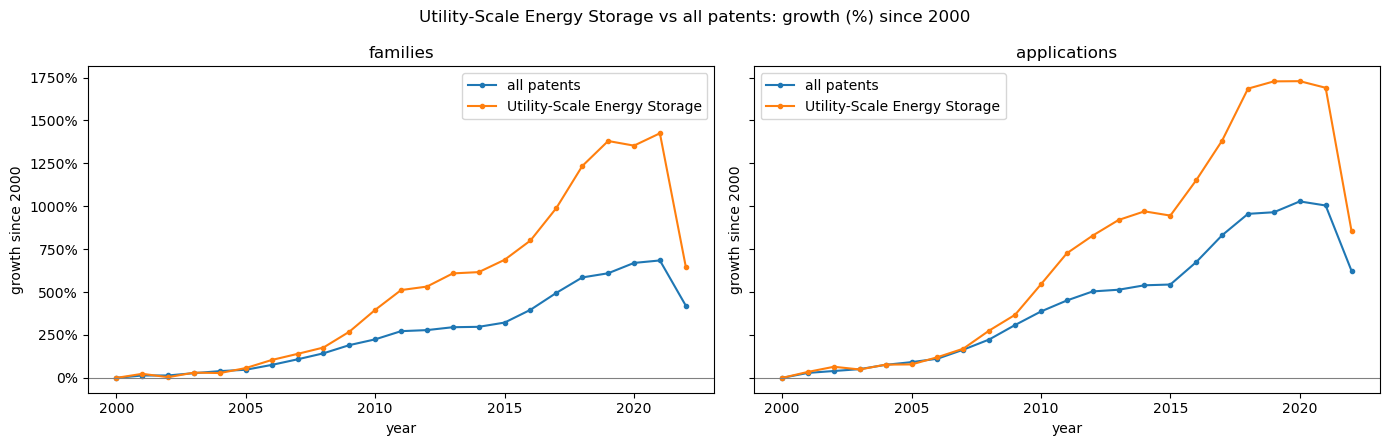

In [12]:
# ==============================================================================
# SECTION 7.2: Growth relative to benchmark ("All Patents")
# ==============================================================================

start, end = YEAR_MIN, LAST_COMPLETE_YEAR
totals = volume.query("series == 'all'").pivot_table(index="year", columns=["level", "scope"], values="n")

# Tabella di sintesi della crescita percentuale (2000 vs 2022)
growth = pd.DataFrame({
    f"count in {start}": totals.loc[start],
    f"count in {end}": totals.loc[end],
    f"growth {start}-{end} (%)": (totals.loc[end] / totals.loc[start] - 1) * 100,
}).loc[[(lvl, s) for lvl in LEVELS for s in ("all patents", SECTOR_NAME)]]

print(f"SUMMARY TABLE: Growth ({start}–{end})")
display(
    growth.style.format({
        f"count in {start}": "{:,.0f}",
        f"count in {end}": "{:,.0f}",
        f"growth {start}-{end} (%)": "{:+.1f}%"
    })
)

# Traiettoria di crescita cumulativa anno per anno (%) rispetto all'anno iniziale
growth_path = (totals.loc[start:end] / totals.loc[start] - 1) * 100

fig, axes = side_by_side(f"{SECTOR_NAME} vs all patents: growth (%) since {start}", sharey=True)
for ax, level in zip(axes, LEVELS):
    for scope_name in ("all patents", SECTOR_NAME):
        ax.plot(growth_path.index, growth_path[(level, scope_name)], marker="o", ms=3, label=scope_name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=UNIT_LABEL[level], xlabel="year", ylabel=f"growth since {start}")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sector_growth_vs_benchmark.png", dpi=300)
plt.show()

## Technology mix

CPC SUBCLASSES SHARE TABLE:


level,family,application,definition (fill in from the CPC scheme)
subclass,,,
Y02E,25.1%,24.0%,"Reduction of greenhouse gas emissions, related to energy generation, transmission or distribution"
H02J,21.8%,20.1%,Circuit arrangements or systems for supplying or distributing electric power; systems for storing electrical energy
Y04S,4.9%,4.5%,"Systems integrating technologies related to power network operation, communication or information technologies for improving the electrical power grid"
G06Q,4.6%,3.7%,"Data processing systems or methods, specially adapted for administrative, commercial, financial, managerial, supervisory or forecasting purposes"
H02M,4.1%,4.2%,"Apparatus for conversion between AC and AC, between AC and DC, or between DC and DC, and for use with mains or similar power supply systems"
F03D,3.9%,6.3%,Wind motors
G06F,3.2%,0.0%,Electric digital data processing
Y02B,3.1%,3.0%,Buildings relating to energy efficiency; Indexing scheme for climate change mitigation technologies
F05B,0.0%,3.5%,Indexing scheme relating to wind motors and hydrodynamic flow machines


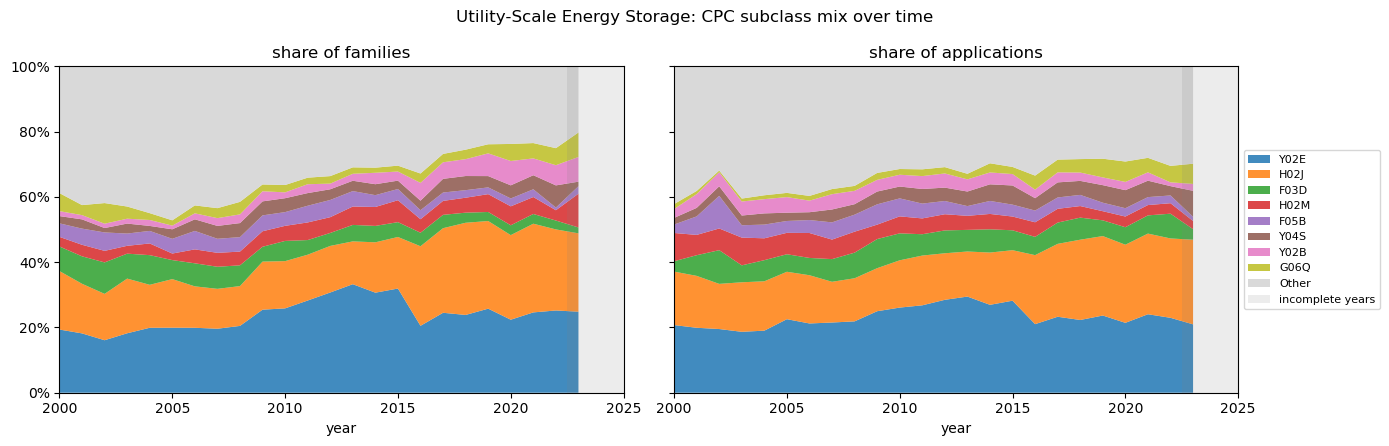


 MACRO-SECTIONS BREAKDOWN (CPC Section Letter):


level,family,application,section_description
cpc_section,,,
Y,33.1%,31.5%,Y - Climate Change Mitigation & Smart Grids
H,25.9%,24.3%,H - Electricity (Power Grid & Electronics Hardware)
G,7.8%,3.7%,"G - Physics (Software, AI, BMS & Trading Algorithms)"
F,3.9%,9.8%,F - Mechanical Engineering (Wind & Hydro Hybrids)
Other,29.3%,30.7%,Other / Secondary CPC Sections
Total,100.0%,100.0%,Total Across Sector


In [16]:
# ==============================================================================
# SECTION 8.1: CPC Subclasses Breakdown & Mix Over Time
# ==============================================================================

# 1. Compute fractional counts by CPC subclass for sector scopes
cpc_mix = pd.concat([fractional_by_cpc_subclass(s) for s in SECTOR_SCOPES], ignore_index=True)

# 2. Pool smaller subclasses into 'Other'
cpc_pooled = pd.concat([
    pool_other(cpc_mix[cpc_mix["level"] == lvl], "subclass").assign(level=lvl)
    for lvl in LEVELS
], ignore_index=True)

# 3. Aggregate totals over complete years (<= LAST_COMPLETE_YEAR)
cpc_counts = complete_years(cpc_pooled).pivot_table(
    index="subclass", columns="level", values="n_frac", aggfunc="sum", fill_value=0
)[list(LEVELS)]

CPC_DEFINITIONS = {
    "Y02E": "Reduction of greenhouse gas emissions, related to energy generation, transmission or distribution",
    "H02J": "Circuit arrangements or systems for supplying or distributing electric power; systems for storing electrical energy",
    "Y04S": "Systems integrating technologies related to power network operation, communication or information technologies for improving the electrical power grid",
    "G06Q": "Data processing systems or methods, specially adapted for administrative, commercial, financial, managerial, supervisory or forecasting purposes",
    "H02M": "Apparatus for conversion between AC and AC, between AC and DC, or between DC and DC, and for use with mains or similar power supply systems",
    "F03D": "Wind motors",
    "G06F": "Electric digital data processing",
    "Y02B": "Buildings relating to energy efficiency; Indexing scheme for climate change mitigation technologies",
    "F05B": "Indexing scheme relating to wind motors and hydrodynamic flow machines",
    "Other": "Other secondary CPC subclasses (e.g., battery chemistry H01M, hydro power F03B)",
    "Total": "Total across the sector",
}

cpc_shares = share_table(cpc_counts)
cpc_shares["definition (fill in from the CPC scheme)"] = [
    CPC_DEFINITIONS.get(subclass, "Definition unavailable")
    for subclass in cpc_shares.index
]

print("CPC SUBCLASSES SHARE TABLE:")
display(cpc_shares.style.format("{:.1f}%", subset=list(LEVELS)))

# 4. Visualization: Stacked 100% Area Chart over time
fig, axes = side_by_side(f"{SECTOR_NAME}: CPC subclass mix over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(
        ax, 
        share_over_time(cpc_pooled[cpc_pooled["level"] == level], "subclass"),
        f"share of {UNIT_LABEL[level]}"
    )
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cpc_subclass_mix_over_time.png", dpi=300)
plt.show()

# 5. Macro-Sections Breakdown by CPC Section Letter (Y, H, G, F)
cpc_section_counts = cpc_counts.reset_index().copy()
cpc_section_counts["cpc_section"] = cpc_section_counts["subclass"].apply(
    lambda x: x[0] if x != "Other" else "Other"
)

macro_section_shares = share_table(
    cpc_section_counts.groupby("cpc_section")[list(LEVELS)].sum()
)

CPC_SECTION_NAMES = {
    "Y": "Y - Climate Change Mitigation & Smart Grids",
    "H": "H - Electricity (Power Grid & Electronics Hardware)",
    "G": "G - Physics (Software, AI, BMS & Trading Algorithms)",
    "F": "F - Mechanical Engineering (Wind & Hydro Hybrids)",
    "Other": "Other / Secondary CPC Sections",
    "Total": "Total Across Sector",
}

macro_section_shares["section_description"] = [
    CPC_SECTION_NAMES.get(sec, "Other Section") for sec in macro_section_shares.index
]

print("\n MACRO-SECTIONS BREAKDOWN (CPC Section Letter):")
display(macro_section_shares.style.format("{:.1f}%", subset=list(LEVELS)))

WIPO MACRO-SECTOR SHARES (%):


level,family,application
techn_sector,,
Electrical engineering,74.8%,70.6%
Mechanical engineering,15.2%,19.7%
Instruments,9.1%,8.9%
Chemistry,0.4%,0.4%
Other fields,0.4%,0.4%
Total,100.0%,100.0%


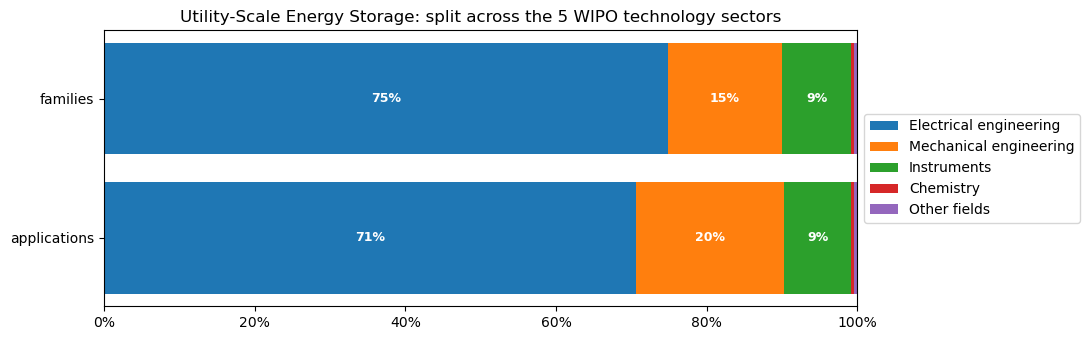


 TOP WIPO SPECIFIC TECHNOLOGY FIELDS:


level,family,application
techn_field,,
"Electrical machinery, apparatus, energy",57.2%,55.3%
"Engines, pumps, turbines",10.5%,15.2%
IT methods for management,7.0%,5.6%
Computer technology,6.9%,6.0%
Control,4.7%,4.8%
Measurement,4.4%,4.1%
Transport,2.8%,2.6%
Digital communication,1.8%,1.8%
Other,4.7%,4.7%


In [17]:
# ==============================================================================
# SECTION 8.2: WIPO Technology Sectors & Fields
# ==============================================================================
from epo.tipdata.patstat.database.models import TLS901_TECHN_FIELD_IPC

# 1. Extract WIPO field and sector names mapping
field_names = patstat.df(
    db.query(
        TLS901_TECHN_FIELD_IPC.techn_field_nr, 
        TLS901_TECHN_FIELD_IPC.techn_field,
        TLS901_TECHN_FIELD_IPC.techn_sector
    ).distinct()
).drop_duplicates("techn_field_nr")

# 2. Compute fractional counts by WIPO technology field
fields = (
    pd.concat([fractional_by_techn_field(s) for s in SECTOR_SCOPES], ignore_index=True)
    .merge(field_names, on="techn_field_nr", how="left")
)

# 3. Aggregate by 5 WIPO Macro-Sectors
techn_sector_counts = complete_years(fields).pivot_table(
    index="techn_sector", columns="level", values="n_frac", aggfunc="sum", fill_value=0
)[list(LEVELS)]

techn_sector_shares = share_table(techn_sector_counts)

print("WIPO MACRO-SECTOR SHARES (%):")
display(pct_format(techn_sector_shares))

# 4. Plot Horizontal Stacked Bar Chart for 5 WIPO Sectors
bars = techn_sector_shares.drop("Total").T

fig, ax = plt.subplots(figsize=(11, 3.5))
left = np.zeros(len(bars))
for techn_sector in bars.columns:
    values = bars[techn_sector].values
    ax.barh([UNIT_LABEL[l] for l in bars.index], values, left=left, label=techn_sector)
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 5:
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    left += values

ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "wipo_technology_sectors.png", dpi=300)
plt.show()

# 5. Top Specific WIPO Technology Fields Breakdown
field_counts = complete_years(fields).pivot_table(
    index="techn_field", columns="level", values="n_frac", aggfunc="sum", fill_value=0
)[list(LEVELS)]

top_fields = field_counts["family"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()

print("\n TOP WIPO SPECIFIC TECHNOLOGY FIELDS:")
display(pct_format(share_table(field_counts)))

## Geography

 Share of sector applications filed at IP5 offices: 84.9%


,applications
office,
CN,45.4%
US,26.5%
WO,7.2%
EP,6.5%
JP,4.1%
KR,2.4%
Other,7.9%
Total,100.0%


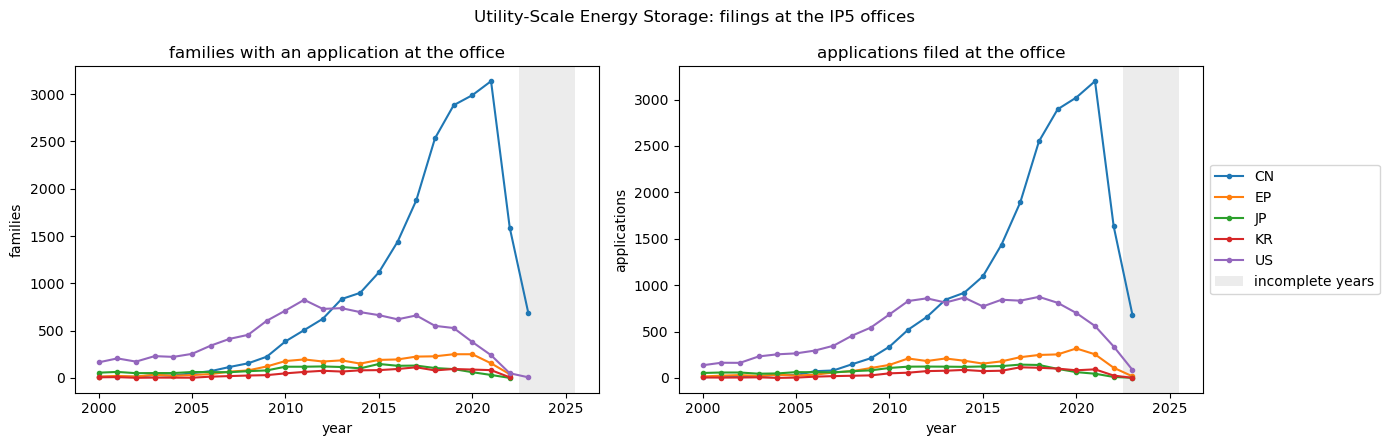

In [21]:
# ==============================================================================
# SECTION 9.1: Filing Offices (IP5 Offices: CN, US, EP, JP, KR)
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd

# 1. Aggregate counts by office and scope
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)

# 2. Consolidate into IP5 + PCT (WO) + Other
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

# 3. Compute application shares across complete years
office_counts = (
    complete_years(offices.query("level == 'application'"))
    .groupby("office")["n"]
    .sum()
    .to_frame("applications")
)
office_shares = share_table(office_counts)

ip5_total_share = office_shares.loc[list(IP5_OFFICES), "applications"].sum()
print(f" Share of sector applications filed at IP5 offices: {ip5_total_share:.1f}%")
display(pct_format(office_shares))

# 4. Visualization: IP5 filing trends over time
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = (
        "families with an application at the office"
        if level == "family"
        else "applications filed at the office"
    )
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])

axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ip5_filing_offices_over_time.png", dpi=300)
plt.show()

 APPLICANT VS INVENTOR COUNTRY SHARES (%):


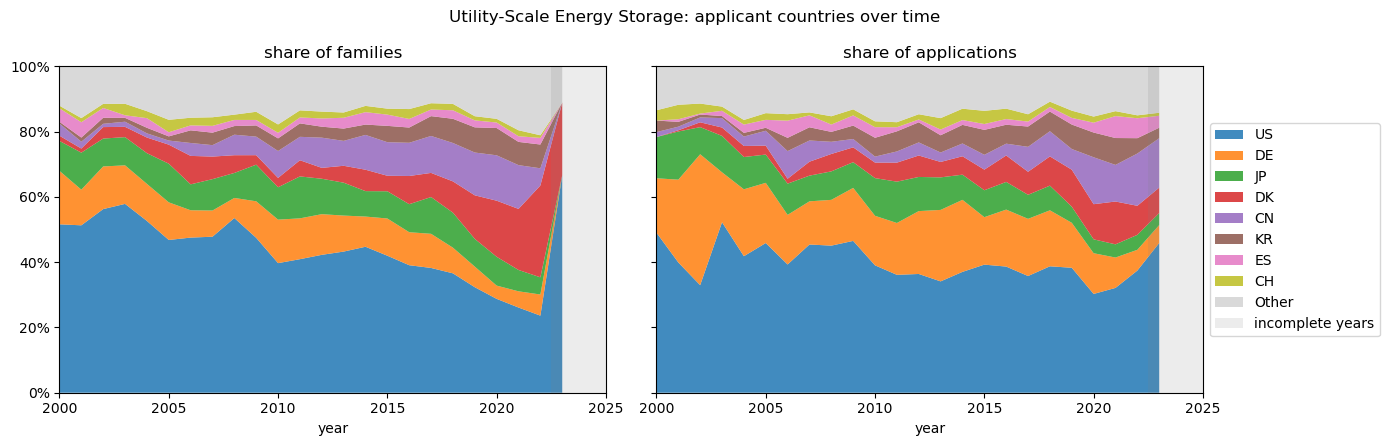

In [20]:
# ==============================================================================
# SECTION 9.2: Applicant and Inventor Countries (Fractional Counts)
# ==============================================================================

# 1. Extract fractional counts for both applicant and inventor roles
countries = pd.concat(
    [
        fractional_by_country(s, role)
        for s in SECTOR_SCOPES
        for role in ("applicant", "inventor")
    ],
    ignore_index=True,
)

# 2. MISSING VALUES FIX: Clean NaN, empty strings, and unassigned country codes
countries["ctry"] = countries["ctry"].fillna("Unknown").replace("", "Unknown")

# 3. Pivot table across complete years
country_counts = complete_years(countries).pivot_table(
    index="ctry",
    columns=["level", "role"],
    values="n_frac",
    aggfunc="sum",
    fill_value=0,
)

# Reorder multi-index columns explicitly
country_counts = country_counts[
    [(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]
]

# Keep top N applicant countries at family level, pool remainder into 'Other'
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(
    country_counts.index.where(country_counts.index.isin(top_countries), "Other")
).sum()

print(" APPLICANT VS INVENTOR COUNTRY SHARES (%):")
display(pct_format(share_table(country_counts)))

# 4. Stacked 100% Area Chart: Applicant country shares over time
fig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(
        ax,
        share_over_time(pool_other(data, "ctry"), "ctry"),
        f"share of {UNIT_LABEL[level]}",
    )

axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "applicant_countries_over_time.png", dpi=300)
plt.show()

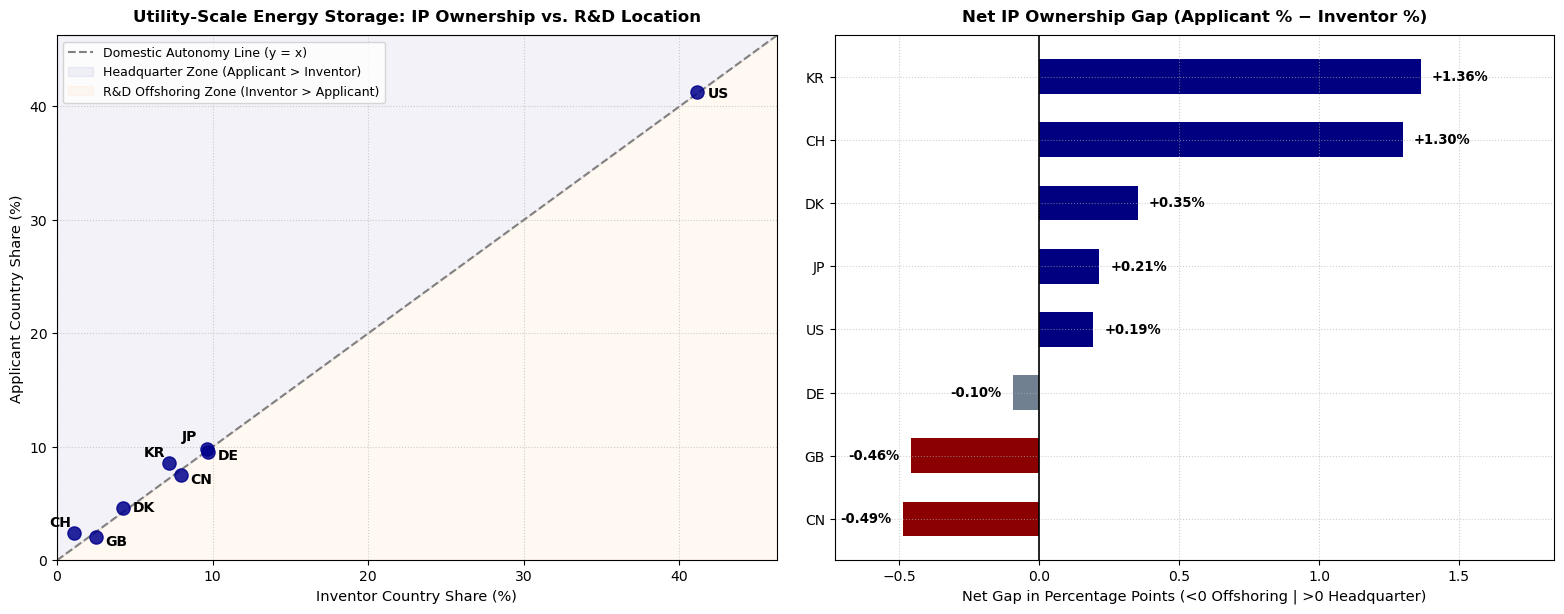

In [24]:
# ==============================================================================
# ADDED SECTION: Visualizing IP Ownership vs. R&D Location (Offshoring & HQ Effects)
# ==============================================================================

# 1. Compute percentage shares using share_table
shares = share_table(country_counts)

# Extract family-level applicant and inventor percentage shares
plot_df = pd.DataFrame(
    {
        "applicant": shares[("family", "applicant")],
        "inventor": shares[("family", "inventor")],
    }
).drop(index=["Total", "Other", "Unknown"], errors="ignore")

# Calculate Net IP Ownership Gap (Applicant Share % - Inventor Share %)
plot_df["gap"] = plot_df["applicant"] - plot_df["inventor"]

# Assign dynamic color mapping based on the gap direction
def assign_gap_color(gap):
    if gap > 0.15:
        return "navy"        # Positive gap (Headquarter Zone)
    elif gap < -0.15:
        return "darkred"     # Negative gap (R&D Offshoring Zone)
    else:
        return "slategray"   # Neutral / Domestic Autonomy

plot_df["color"] = plot_df["gap"].apply(assign_gap_color)

# 2. Create side-by-side visualization with increased figure size
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

# ------------------------------------------------------------------------------
# Subplot 1: Scatter Plot with Custom Non-Overlapping Label Offsets
# ------------------------------------------------------------------------------
max_val = max(plot_df["inventor"].max(), plot_df["applicant"].max()) * 1.12

# Diagonal equality line (y = x)
ax1.plot(
    [0, max_val],
    [0, max_val],
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Domestic Autonomy Line (y = x)",
)

# Background shading for strategic zones
ax1.fill_between(
    [0, max_val],
    [0, max_val],
    max_val,
    color="navy",
    alpha=0.05,
    label="Headquarter Zone (Applicant > Inventor)",
)
ax1.fill_between(
    [0, max_val],
    0,
    [0, max_val],
    color="darkorange",
    alpha=0.05,
    label="R&D Offshoring Zone (Inventor > Applicant)",
)

# Plot country points
ax1.scatter(
    plot_df["inventor"],
    plot_df["applicant"],
    color="darkblue",
    s=90,
    zorder=4,
    alpha=0.85,
)

# Custom manual text offsets (x, y points offset) to prevent overlapping labels
LABEL_OFFSETS = {
    "US": (8, -4),
    "DE": (7, -6),
    "JP": (-18, 6),
    "CN": (7, -6),
    "KR": (-18, 5),
    "DK": (7, -2),
    "GB": (7, -6),
    "CH": (-18, 5),
}

for ctry, row in plot_df.iterrows():
  offset = LABEL_OFFSETS.get(ctry, (6, 4))
  ax1.annotate(
      ctry,
      (row["inventor"], row["applicant"]),
      xytext=offset,
      textcoords="offset points",
      fontsize=10,
      fontweight="bold",
      color=row["color"]
  )

ax1.set_title(
    f"{SECTOR_NAME}: IP Ownership vs. R&D Location",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.set_xlabel("Inventor Country Share (%)", fontsize=10.5)
ax1.set_ylabel("Applicant Country Share (%)", fontsize=10.5)
ax1.set_xlim(0, max_val)
ax1.set_ylim(0, max_val)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper left", fontsize=9)

# ------------------------------------------------------------------------------
# Subplot 2: Diverging Bar Chart with Fixed Padding & Alignment
# ------------------------------------------------------------------------------
sorted_gap = plot_df.sort_values("gap", ascending=True)

# Colors: Dark Red for negative gap, Navy for positive gap, SlateGray for neutral

bars = ax2.barh(sorted_gap.index, sorted_gap["gap"], color=bar_colors, height=0.55)

# Calculate explicit x-axis bounds to prevent text clipping on the left border
min_gap = sorted_gap["gap"].min()
max_gap = sorted_gap["gap"].max()
x_margin_left = min_gap * 1.5 if min_gap < 0 else -0.5
x_margin_right = max_gap * 1.35 if max_gap > 0 else 0.5
ax2.set_xlim(x_margin_left, x_margin_right)

# Annotate gap values with proper alignment and spacing
for bar in bars:
  width = bar.get_width()
  y_pos = bar.get_y() + bar.get_height() / 2

  if width >= 0:
    ax2.text(
        width + 0.04,
        y_pos,
        f"+{width:.2f}%",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold",
    )
  else:
    ax2.text(
        width - 0.04,
        y_pos,
        f"{width:.2f}%",
        va="center",
        ha="right",
        fontsize=9.5,
        fontweight="bold",
    )

ax2.axvline(0, color="black", linewidth=1.2)
ax2.set_title(
    "Net IP Ownership Gap (Applicant % − Inventor %)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel(
    "Net Gap in Percentage Points (<0 Offshoring | >0 Headquarter)",
    fontsize=10.5,
)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout(pad=2.0)
plt.savefig(
    OUTPUT_DIR / "applicant_vs_inventor_gap_analysis.png", dpi=300
)
plt.show()